# Exploratory Data Analysis (EDA): Target (tma_mdpl)

Fokus EDA:
1. **Distribusi & outlier per pos** - Mencari lonjakan liar (outliers) dan mencegah model belajar dari noise sensor.
2. **Trend musiman (musim hujan vs kemarau)** - Menentukan apakah perlu fitur seasonal/cyclical (bulan, hari-dalam-tahun).
3. **Autokorelasi (ACF/PACF) per pos** - Menentukan berapa banyak lag yang relevan untuk fitur autokorelasi.
4. **Perbandingan level TMA antar pos yang searah sungai** - Konfirmasi hubungan hulu-hilir (validasi fitur upstream).

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings('ignore')
plt.style.use('ggplot')

## Load Data
Kita memuat data train dan mengubah kolom `datetime`.

In [11]:
# Load data train
df_train = pd.read_csv('../train.csv')
df_train['datetime'] = pd.to_datetime(df_train['datetime'])
df_train.sort_values(by=['nama_pos', 'datetime'], inplace=True)

print("Shape data train:", df_train.shape)
display(df_train.head())

Shape data train: (84396, 3)


,datetime,nama_pos,tma_mdpl
0,2023-01-01 06:00:00,Arjowinangun - Pacitan,1.30
1,2023-01-01 12:00:00,Arjowinangun - Pacitan,1.20
2,2023-01-01 18:00:00,Arjowinangun - Pacitan,1.50
3,2023-01-02 06:00:00,Arjowinangun - Pacitan,1.45
4,2023-01-02 12:00:00,Arjowinangun - Pacitan,1.25


## 1. Distribusi & Outlier per Pos
Kita melihat distribusi `tma_mdpl` menggunakan boxplot untuk memvisualisasikan adanya lonjakan liar dari sensor.

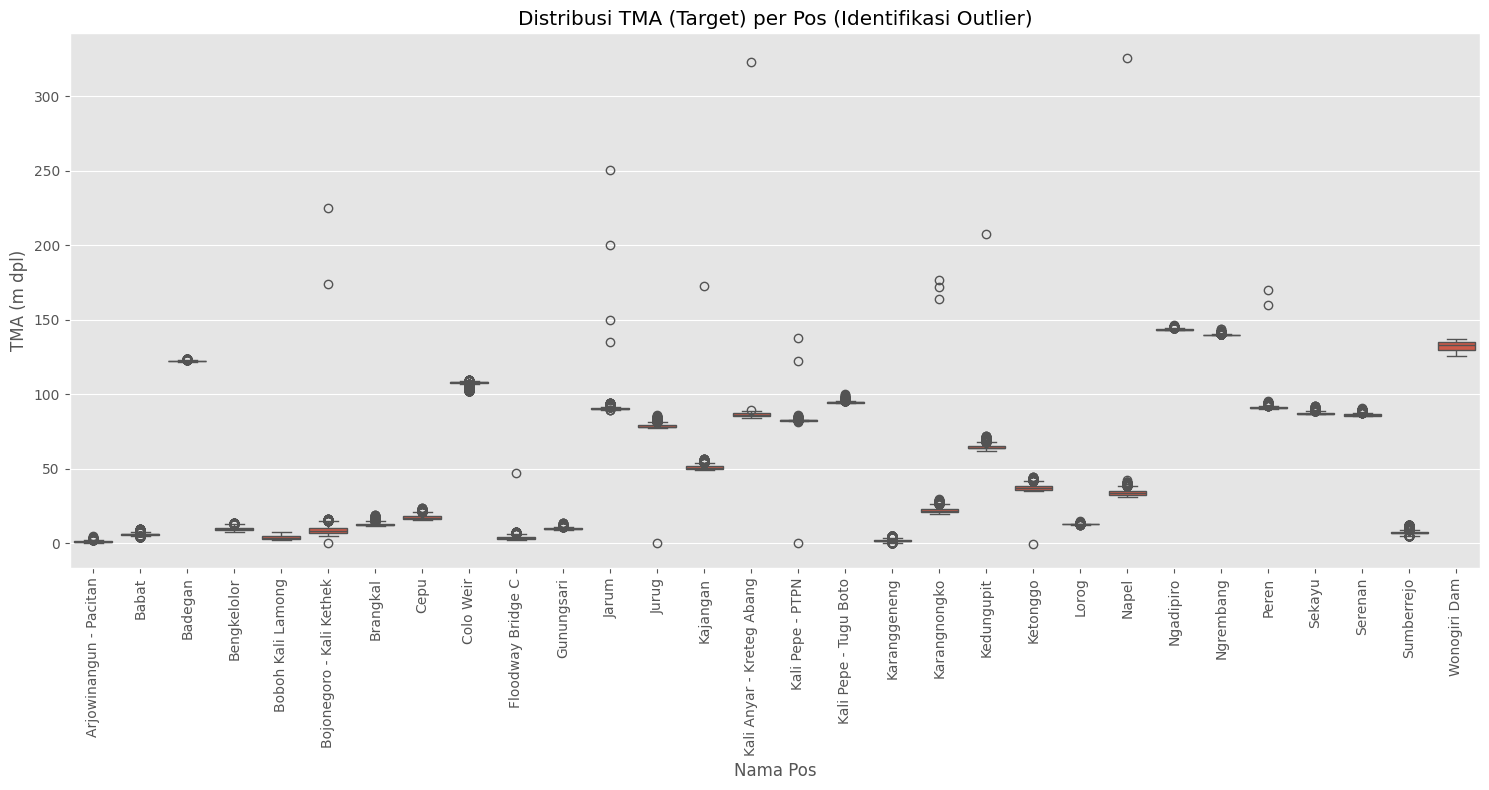

In [12]:
plt.figure(figsize=(15, 8))
sns.boxplot(data=df_train, x='nama_pos', y='tma_mdpl')
plt.xticks(rotation=90)
plt.title('Distribusi TMA (Target) per Pos (Identifikasi Outlier)')
plt.ylabel('TMA (m dpl)')
plt.xlabel('Nama Pos')
plt.tight_layout()
plt.show()

Kita juga mengecek time-series mentah untuk beberapa pos, untuk melihat apakah outlier tersebut hanyalah *noise* (spike sesaat) atau memang pergerakan banjir asli.

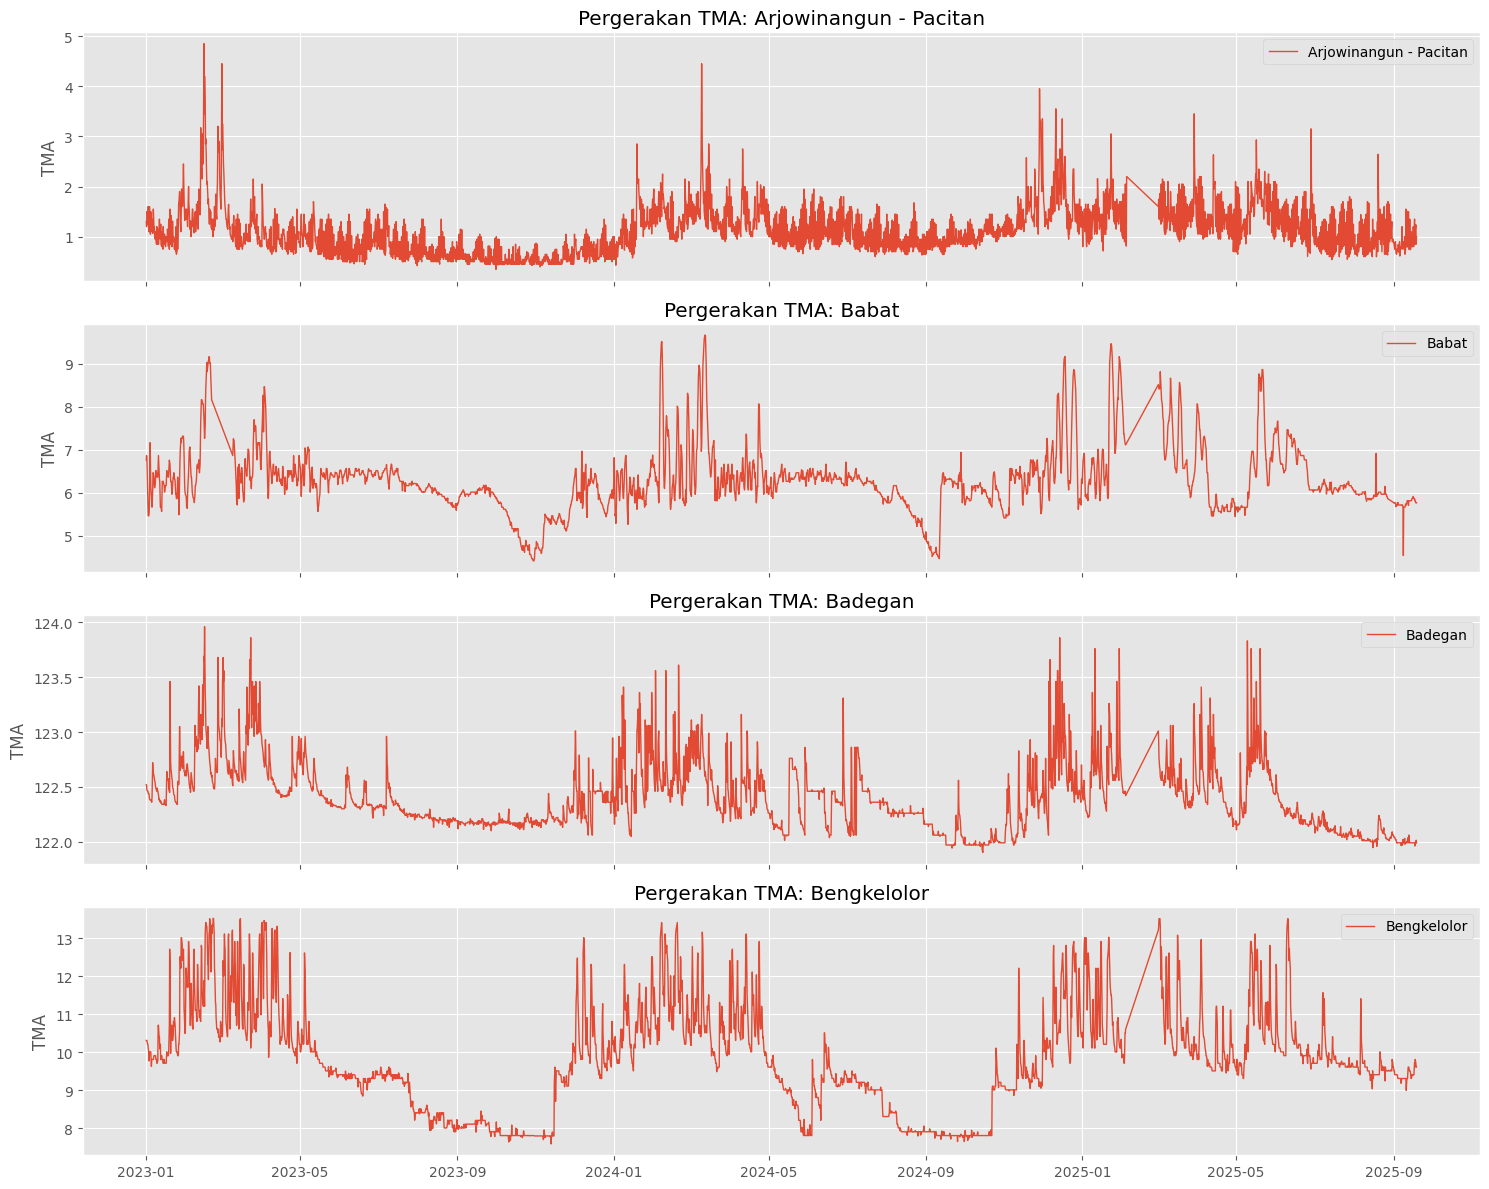

In [13]:
# Plot time series untuk 4 pos sampel
sample_pos = df_train['nama_pos'].unique()[:4]
fig, axes = plt.subplots(len(sample_pos), 1, figsize=(15, 3*len(sample_pos)), sharex=True)

for i, pos in enumerate(sample_pos):
    data_pos = df_train[df_train['nama_pos'] == pos]
    axes[i].plot(data_pos['datetime'], data_pos['tma_mdpl'], label=pos, linewidth=1)
    axes[i].set_title(f'Pergerakan TMA: {pos}')
    axes[i].set_ylabel('TMA')
    axes[i].legend(loc='upper right')
    
plt.tight_layout()
plt.show()

## 2. Trend Musiman (Musim Hujan vs Kemarau)
Ekstraksi bulan untuk mengecek apakah ada pola berulang (misal tinggi di akhir/awal tahun).

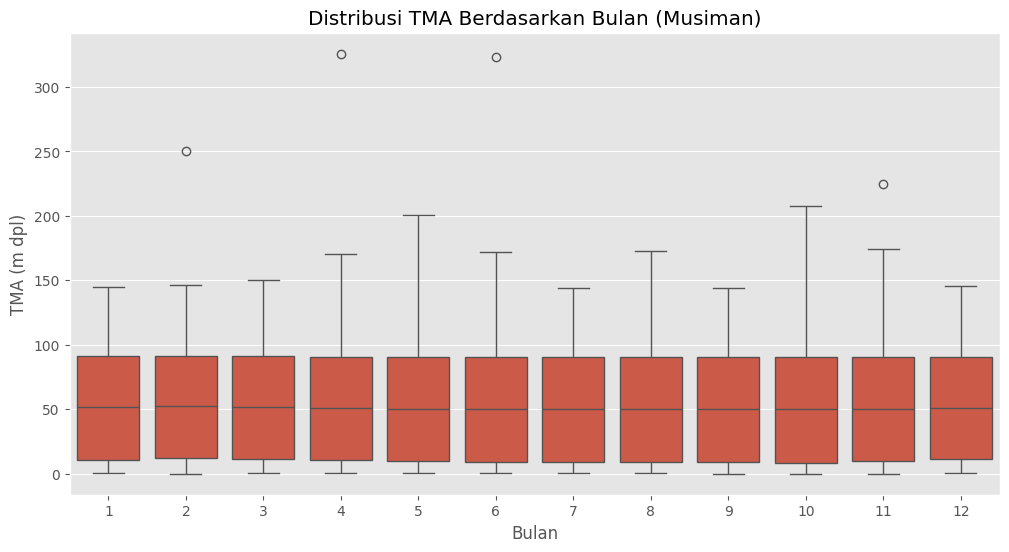

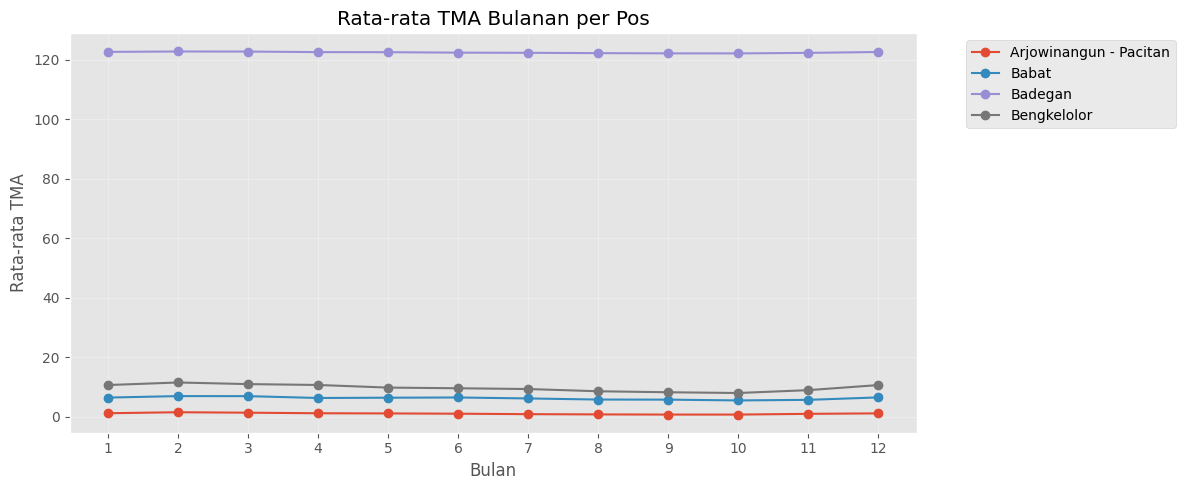

In [14]:
df_train['bulan'] = df_train['datetime'].dt.month

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_train, x='bulan', y='tma_mdpl')
plt.title('Distribusi TMA Berdasarkan Bulan (Musiman)')
plt.xlabel('Bulan')
plt.ylabel('TMA (m dpl)')
plt.show()

# Rata-rata per bulan untuk beberapa pos contoh
monthly_avg = df_train.groupby(['nama_pos', 'bulan'])['tma_mdpl'].mean().unstack(level=0)
monthly_avg[sample_pos].plot(figsize=(12, 5), marker='o')
plt.title('Rata-rata TMA Bulanan per Pos')
plt.xlabel('Bulan')
plt.ylabel('Rata-rata TMA')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 3. Autokorelasi (ACF/PACF) per Pos
ACF/PACF digunakan untuk melihat korelasi TMA dengan nilai sebelumnya (lag). Jika lag tinggi di ACF, berarti respon sungai lambat (kemungkinan sungai besar). Membantu menentukan batas window size/lags untuk features.

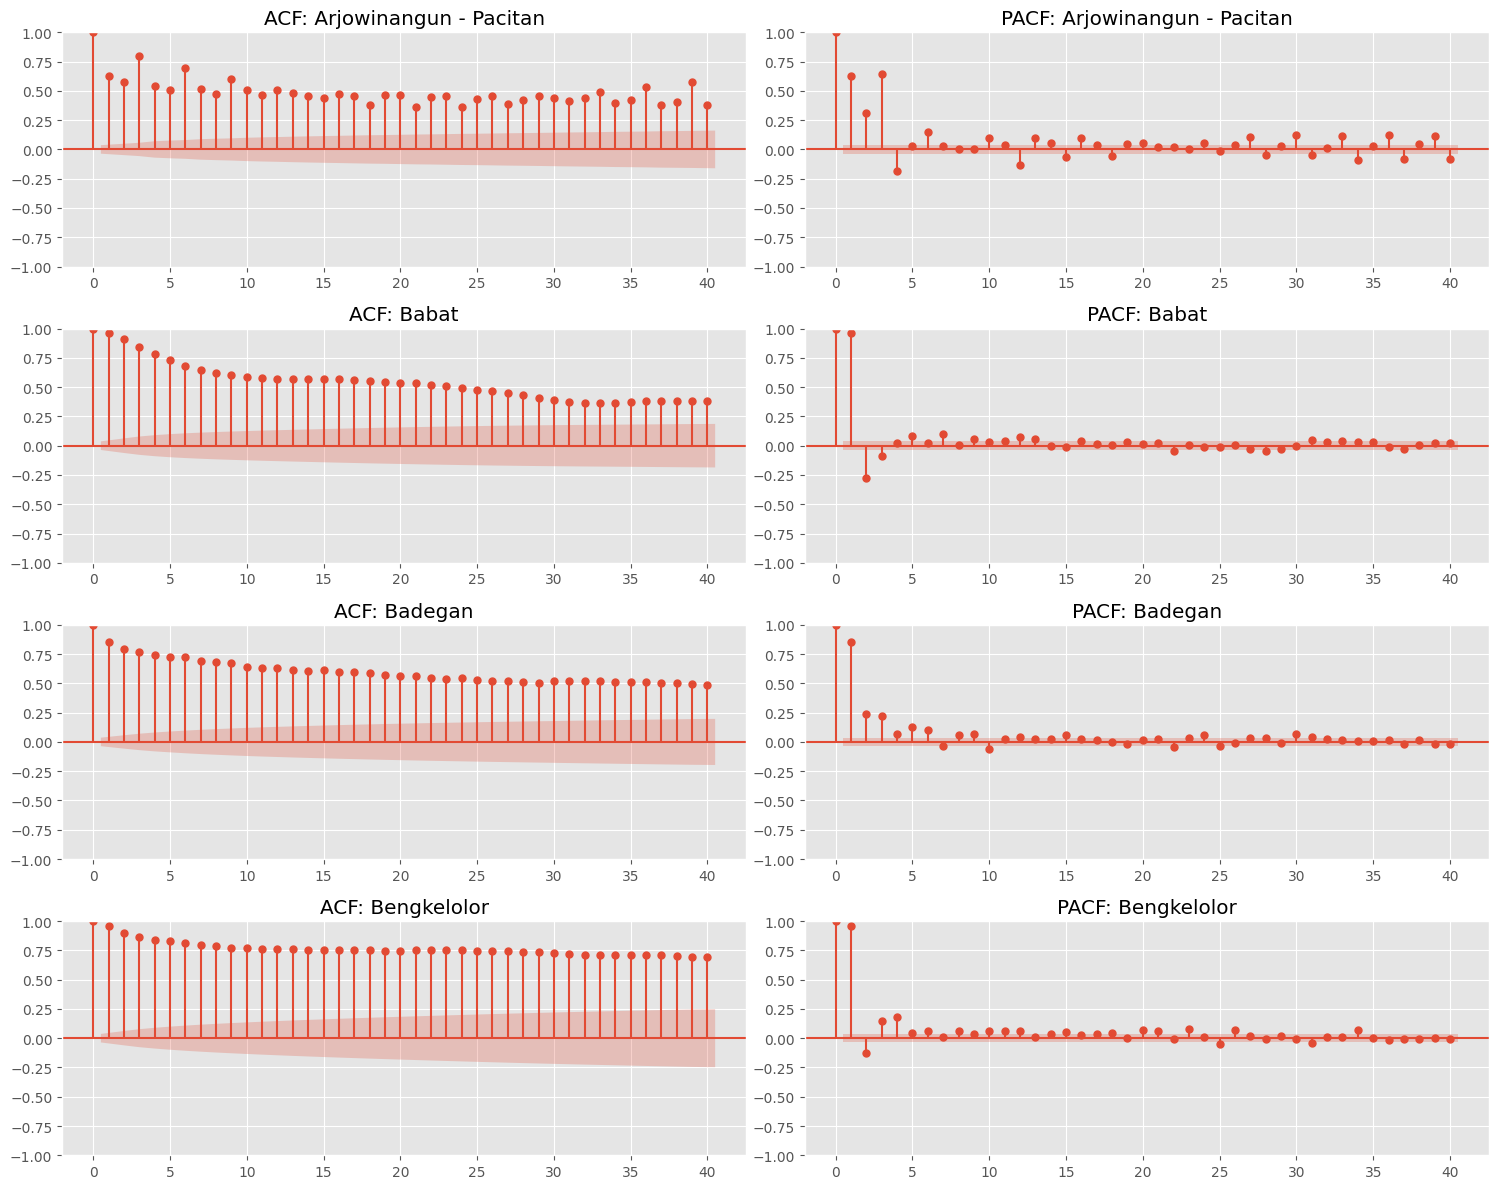

In [15]:
lags_to_check = 40  # lag steps
fig, axes = plt.subplots(len(sample_pos), 2, figsize=(15, 3*len(sample_pos)))

for i, pos in enumerate(sample_pos):
    data_pos = df_train[df_train['nama_pos'] == pos].set_index('datetime')['tma_mdpl']
    data_pos = data_pos.ffill().dropna()
    
    if len(data_pos) > lags_to_check:
        plot_acf(data_pos, lags=lags_to_check, ax=axes[i, 0], title=f'ACF: {pos}')
        plot_pacf(data_pos, lags=lags_to_check, ax=axes[i, 1], title=f'PACF: {pos}')

plt.tight_layout()
plt.show()

## 4. Perbandingan Level TMA antar Pos yang Searah Sungai
Mengecek korelasi antar pos. Pos hulu dan hilir yang berada di sungai yang sama harusnya punya korelasi yang cukup terlihat.

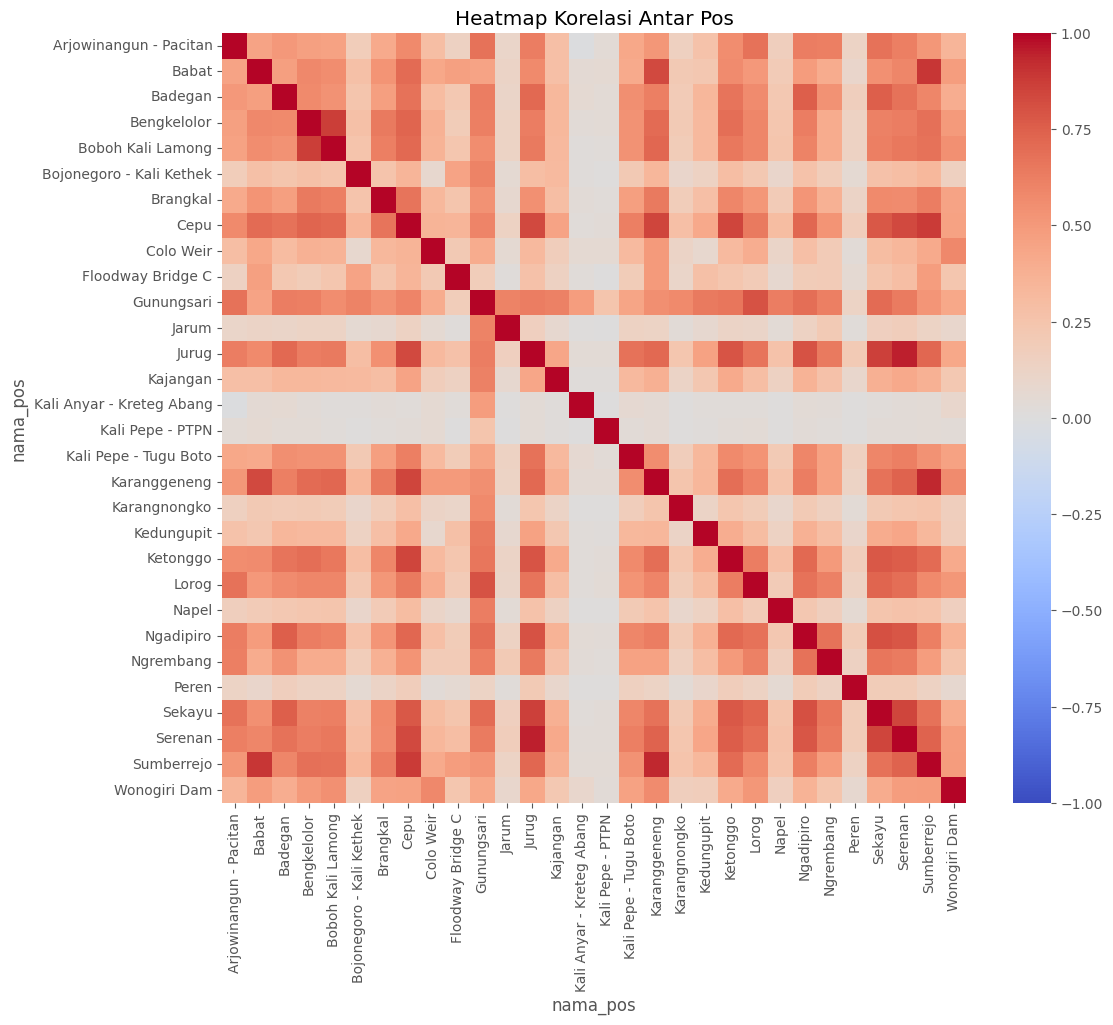

In [16]:
# Pivot agar baris = datetime, kolom = pos
df_pivot = df_train.pivot_table(index='datetime', columns='nama_pos', values='tma_mdpl')

# Korelasi matriks (Spearman seringkali lebih baik untuk sinyal rank / non-linear, tapi Pearson oke sebagai awalan)
corr_matrix = df_pivot.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Antar Pos')
plt.show()

Visualisasi pos dengan korelasi tertinggi (asumsi hulu-hilir kuat).

-> Pasangan pos paling berkorelasi: Jurug & Serenan (0.946)


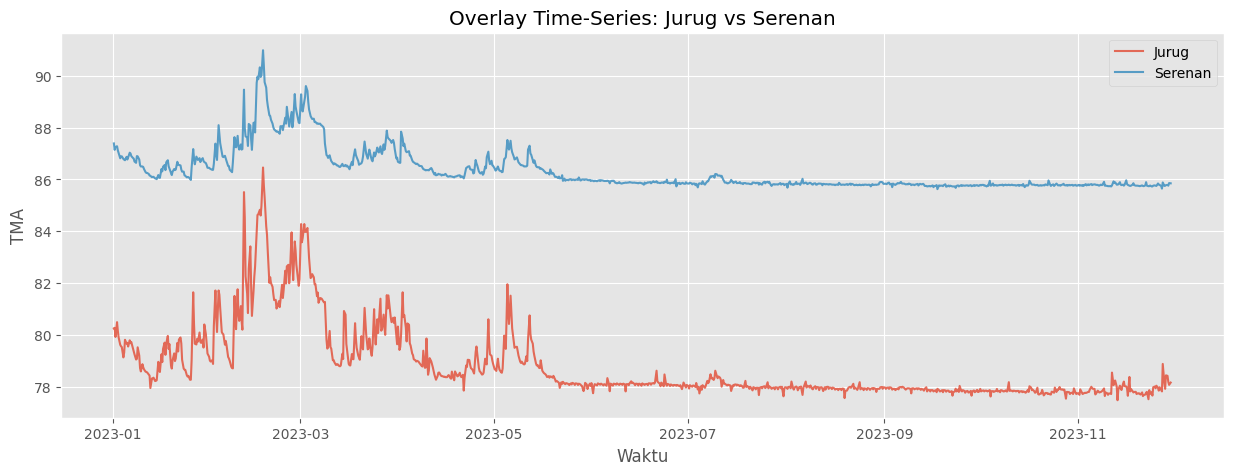

In [17]:
corr_pairs = corr_matrix.unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 0.999]  # Drop self-correlation (1.0)

if len(corr_pairs) > 0:
    pos1, pos2 = corr_pairs.index[0]
    print(f"-> Pasangan pos paling berkorelasi: {pos1} & {pos2} ({corr_pairs.iloc[0]:.3f})")
    
    # Kita tampilkan plot untuk 1000 data point pertama yang tidak kosong pada keduanya
    subset = df_pivot[[pos1, pos2]].dropna().head(1000)
    
    plt.figure(figsize=(15, 5))
    plt.plot(subset.index, subset[pos1], label=pos1, alpha=0.8)
    plt.plot(subset.index, subset[pos2], label=pos2, alpha=0.8)
    plt.title(f'Overlay Time-Series: {pos1} vs {pos2}')
    plt.ylabel('TMA')
    plt.xlabel('Waktu')
    plt.legend()
    plt.show()
else:
    print("Belum cukup data untuk plot korelasi pasangan.")

---
## Exploratory Data Analysis (EDA): Fitur Eksogen (`data_lingkungan.csv`)

Fokus EDA:
1. **Korelasi rainfall_mm vs rainfall_openmeteo_mm** - Mengetahui apakah dua fitur curah hujan ini saling melengkapi atau redundan.
2. **Distribusi & missing value per fitur cuaca** - Mengecek pola missing value dan dominasi nol pada data cuaca.
3. **Korelasi antar 4 layer soil moisture** - Evaluasi kemungkinan redundansi sehingga dapat disederhanakan.
4. **Resolusi temporal mismatch & Lag/lead relationship** - Mengatasi beda resolusi (per jam vs per 6 jam) dengan agregasi yang sesuai lalu melihat *response time* hujan ke target.
5. **RMM1/RMM2/MJO/Nino3.4** - Mengecek granularity fitur cuaca makro (slow-varying features) agar tidak menyebabkan overfitting ke pola lambat.

In [ ]:
# Load data lingkungan
df_env = pd.read_csv('../data_pendukung/data_lingkungan.csv')
df_env['datetime'] = pd.to_datetime(df_env['datetime'])
df_env.sort_values(by=['nama_pos', 'datetime'], inplace=True)
print("Shape data lingkungan:", df_env.shape)
display(df_env.head(3))

### 1. Korelasi rainfall_mm vs rainfall_openmeteo_mm

In [ ]:
# Scatter plot dan korelasi antara rainfall observed dan openmeteo
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_env.sample(10000, random_state=42), x='rainfall_mm', y='rainfall_openmeteo_mm', alpha=0.3)
plt.title('Korelasi rainfall_mm vs rainfall_openmeteo_mm (Sample 10k)')
plt.xlabel('Rainfall (Observed/Station) - mm')
plt.ylabel('Rainfall (OpenMeteo) - mm')

corr_rain = df_env['rainfall_mm'].corr(df_env['rainfall_openmeteo_mm'])
plt.text(0.05, 0.95, f'Korelasi Pearson: {corr_rain:.3f}', transform=plt.gca().transAxes, fontsize=12,
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.show()

# Cek persentase nol
pct_zero_obs = (df_env['rainfall_mm'] == 0).mean() * 100
pct_zero_om = (df_env['rainfall_openmeteo_mm'] == 0).mean() * 100
print(f"Persentase curah hujan 0 (Observed) : {pct_zero_obs:.2f}%")
print(f"Persentase curah hujan 0 (OpenMeteo): {pct_zero_om:.2f}%")

### 2. Distribusi & Missing Value per Fitur Cuaca

In [ ]:
weather_features = ['rainfall_mm', 'humidity_pct', 'temperature_c', 'wind_speed_kmh', 'solar_radiation_mj_m2']

# Cek Missing Values
missing = df_env[weather_features].isnull().sum()
missing_pct = (missing / len(df_env)) * 100
print("Missing Value pada Fitur Cuaca:")
display(pd.DataFrame({'Missing': missing, 'Percentage (%)': missing_pct}))

# Plot Distribusi (untuk nilai yang non-zero agar pola selain nol terlihat)
fig, axes = plt.subplots(1, len(weather_features), figsize=(20, 4))
for i, feat in enumerate(weather_features):
    if feat in ['rainfall_mm', 'solar_radiation_mj_m2']:
        data_to_plot = df_env[df_env[feat] > 0][feat].dropna()
        axes[i].set_title(f'{feat} (> 0)')
    else:
        data_to_plot = df_env[feat].dropna()
        axes[i].set_title(feat)
    
    sns.histplot(data_to_plot, bins=30, ax=axes[i], kde=True)

plt.tight_layout()
plt.show()

### 3. Korelasi antar 4 Layer Soil Moisture

In [ ]:
soil_features = ['soil_moisture_0_7cm', 'soil_moisture_7_28cm', 'soil_moisture_28_100cm', 'soil_moisture_100_255cm']

soil_corr = df_env[soil_features].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(soil_corr, annot=True, cmap='viridis', vmin=0, vmax=1)
plt.title('Korelasi antar layer Soil Moisture')
plt.show()

# Kesimpulan sementara: Jika korelasi antar layer atas sangat tinggi, kita bisa mempertimbangkan untuk mengambil rata-ratanya, atau sekadar memilih layer yang paling representatif saja (misal layer teratas dan terbawah) daripada memasukkan keempat layer.

### 4 & 5. Resolusi Temporal & Lag/Lead Relationship Rainfall vs TMA
Data `data_lingkungan.csv` beresolusi per 1 jam, target `tma_mdpl` per 6 jam (00, 06, 12, 18). Kita agregasi curah hujan dengan `sum` (akumulasi selama 6 jam), lalu gabungkan ke data train untuk melihat *response time* TMA dari kejadian hujan.

In [ ]:
# Gunakan 1 pos sebagai sampel
pos_example = df_train['nama_pos'].unique()[0]
env_pos = df_env[df_env['nama_pos'] == pos_example].copy()
env_pos.set_index('datetime', inplace=True)

# Resample menjadi 6 jam (00, 06, 12, 18)
# Note: Karena data target ada di 06:00, 12:00, dll, resample '6h' mensejajarkan window 6 jam. Label=right agar hujan dari jam 00-06 masuk ke index 06:00
env_pos_6h = env_pos.resample('6h', label='right').agg({
    'rainfall_mm': 'sum',
    'soil_moisture_0_7cm': 'mean'
})

# Gabung dengan target
train_pos = df_train[df_train['nama_pos'] == pos_example].set_index('datetime')
merged_pos = train_pos.join(env_pos_6h, how='inner')

# Cross-Correlation (Korelasi target TMA dengan Lag Curah Hujan)
lags = range(0, 11)
corr_with_lags = []
for lag in lags:
    shifted_rain = merged_pos['rainfall_mm'].shift(lag)
    corr = merged_pos['tma_mdpl'].corr(shifted_rain)
    corr_with_lags.append(corr)

plt.figure(figsize=(10, 4))
plt.bar(lags, corr_with_lags, color='skyblue')
plt.axhline(0, color='black', lw=1)
plt.title(f'Cross-Correlation TMA vs Lag Rainfall (Pos: {pos_example})')
plt.xlabel('Lag Hujan (1 unit = 6 Jam mundur)')
plt.ylabel('Pearson Correlation')
plt.xticks(lags)
plt.show()

# Visualisasi hydrograph sederhana (Hujan vs TMA)
fig, ax1 = plt.subplots(figsize=(15, 5))
subset = merged_pos.head(250) # Tampilkan 250 data
ax1.plot(subset.index, subset['tma_mdpl'], color='red', label='TMA (mdpl)')
ax1.set_ylabel('TMA', color='red')
ax1.set_xlabel('Waktu')

ax2 = ax1.twinx()
ax2.bar(subset.index, subset['rainfall_mm'], color='blue', alpha=0.3, width=0.1, label='Rainfall (6h sum)')
ax2.set_ylabel('Curah Hujan (mm)', color='blue')
ax2.invert_yaxis() # Supaya mirip standar plot hidrografik

plt.title('Hydrograph Sederhana: Curah Hujan (akumulasi 6 jam) vs Target TMA')
fig.legend(loc="lower left", bbox_to_anchor=(0.1, 0.1))
plt.show()

### 6. RMM1/RMM2/MJO/Nino3.4 — Cek Granularity Temporal
Mengecek laju perubahan fitur indikator global agar tidak terjadi overfitting pada memori jangka panjang tanpa dasar logika fisik.

In [ ]:
macro_features = ['rmm1', 'mjo_phase', 'nino_34']
subset_env = df_env[df_env['nama_pos'] == pos_example].head(24 * 60).reset_index(drop=True) # Data 60 hari

fig, axes = plt.subplots(3, 1, figsize=(15, 7), sharex=True)
for i, feat in enumerate(macro_features):
    axes[i].plot(subset_env.index, subset_env[feat], marker='o', markersize=2)
    axes[i].set_ylabel(feat)
    axes[i].set_title(f'Pergerakan {feat} (Granularitas 1 Jam)')

axes[-1].set_xlabel('Waktu (Jam ke-)')
plt.tight_layout()
plt.show()

Terlihat bahwa `nino_34` hanya berubah pada interval waktu yang cukup lama (bernilai konstan selama berhari-hari/berbulan-bulan). Memakai fitur *slow-varying* secara mentah (tanpa *lag* panjang atau agregasi bulanan) akan berisiko menjadi sumber representasi palsu bagi model mesin learning (model sekadar "menghafal" nilai konstan). 
Direkomendasikan fitur ini di-*drop* atau diturunkan menjadi fitur kategorik (misal fase nino/nina) secara global, alih-alih regressor titik per titik.